In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Air/passengers/archive/AirPassengers.csv")
df

,Month,#Passengers
0,1949-01,112
1,1949-02,118
2,1949-03,132
3,1949-04,129
4,1949-05,121
...,...,...
139,1960-08,606
140,1960-09,508
141,1960-10,461
142,1960-11,390


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense

In [ ]:
print(df.head())
print(df.shape)
print(df.info())

     Month  #Passengers
0  1949-01          112
1  1949-02          118
2  1949-03          132
3  1949-04          129
4  1949-05          121
(144, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 144 entries, 0 to 143
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Month        144 non-null    object
 1   #Passengers  144 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 2.4+ KB
None


Data preprocessing


In [ ]:
print(df.columns.tolist())


['Month', '#Passengers']


In [ ]:
df.columns = df.columns.str.strip()

print(df.columns.tolist())

['Month', '#Passengers']


In [ ]:
df = df.rename(columns={
    '#Passengers': 'Passengers'
})

In [ ]:
print(df.head())
print(df.columns.tolist())

       Month  Passengers
0 1949-01-01         112
1 1949-02-01         118
2 1949-03-01         132
3 1949-04-01         129
4 1949-05-01         121
['Month', 'Passengers']


passengers data prepare

In [ ]:
df['Month'] = pd.to_datetime(df['Month'])

df['Passengers'] = pd.to_numeric(
    df['Passengers'], errors='coerce'
)

df = df.dropna()

data = df[['Passengers']].values

print(data[:5])

[[112]
 [118]
 [132]
 [129]
 [121]]


Normalize

In [ ]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler(feature_range=(0,1))

scaled_data = scaler.fit_transform(data)

print(scaled_data[:5])

[[0.01544402]
 [0.02702703]
 [0.05405405]
 [0.04826255]
 [0.03281853]]


Time Series Data Preparation

In [ ]:
import numpy as np

def create_sequences(data, time_step=12):

    X = []
    y = []

    for i in range(time_step, len(data)):
        X.append(data[i-time_step:i, 0])
        y.append(data[i, 0])

    return np.array(X), np.array(y)


X, y = create_sequences(scaled_data, 12)

print("X Shape:", X.shape)
print("y Shape:", y.shape)

X Shape: (132, 12)
y Shape: (132,)


split

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, shuffle=False
)

X_train = X_train.reshape(X_train.shape[0], 12, 1)
X_test = X_test.reshape(X_test.shape[0], 12, 1)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (105, 12, 1)
X_test: (27, 12, 1)
y_train: (105,)
y_test: (27,)


Build RNN model

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense

model = Sequential()

model.add(SimpleRNN(
    50,
    activation='tanh',
    input_shape=(12, 1)
))

model.add(Dense(1))

model.compile(
    optimizer='adam',
    loss='mean_squared_error',
    metrics=['mae']
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_1 (SimpleRNN)        │ (None, 50)             │         2,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,651 (10.36 KB)

 Trainable params: 2,651 (10.36 KB)

 Non-trainable params: 0 (0.00 B)

Train model

In [ ]:
history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=8,
    validation_split=0.2,
    verbose=1
)

Epoch 1/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - loss: 0.0238 - mae: 0.1160 - val_loss: 0.0338 - val_mae: 0.1540
Epoch 2/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0053 - mae: 0.0510 - val_loss: 0.0069 - val_mae: 0.0569
Epoch 3/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0018 - mae: 0.0330 - val_loss: 0.0063 - val_mae: 0.0585
Epoch 4/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0013 - mae: 0.0269 - val_loss: 0.0044 - val_mae: 0.0506
Epoch 5/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0010 - mae: 0.0254 - val_loss: 0.0041 - val_mae: 0.0501
Epoch 6/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 9.5316e-04 - mae: 0.0240 - val_loss: 0.0033 - val_mae: 0.0445
Epoch 7/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 8.8755e-04 - mae: 0.0233 - val_loss: 0.0035 - val_mae: 0.0466
Epoch 8/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 8.8776e-04 - mae: 0.0233 - val_loss: 0.0029 - val_mae: 0.0427
Epoch 9/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/s

Evaluate model

In [ ]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
import numpy as np

y_pred = model.predict(X_test)

y_pred = scaler.inverse_transform(
    y_pred.reshape(-1, 1)
)

y_actual = scaler.inverse_transform(
    y_test.reshape(-1, 1)
)

mae = mean_absolute_error(y_actual, y_pred)

mse = mean_squared_error(y_actual, y_pred)

rmse = np.sqrt(mse)

mape = np.mean(
    np.abs((y_actual - y_pred) / y_actual)
) * 100

accuracy = 100 - mape

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("MAPE:", mape, "%")
print("Approximate Prediction Accuracy:", accuracy, "%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 379ms/step
MAE: 20.584057843243635
MSE: 608.0697579435936
RMSE: 24.659070500397892
MAPE: 4.625846674550972 %
Approximate Prediction Accuracy: 95.37415332544903 %


Actual vs Predicted Graph

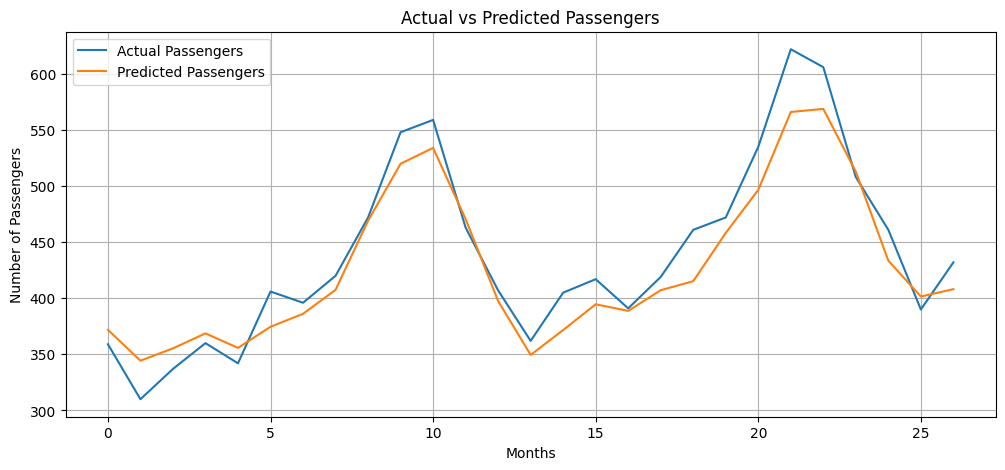

In [ ]:
plt.figure(figsize=(12,5))

plt.plot(y_actual, label='Actual Passengers')

plt.plot(y_pred, label='Predicted Passengers')

plt.title('Actual vs Predicted Passengers')

plt.xlabel('Months')
plt.ylabel('Number of Passengers')

plt.legend()
plt.grid()

plt.show()

Training and Validation Loss Graph

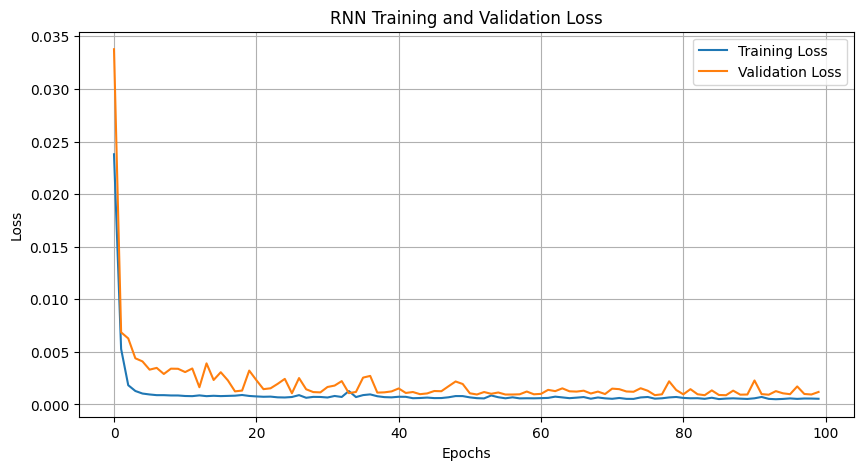

In [ ]:
plt.figure(figsize=(10,5))

plt.plot(history.history['loss'], label='Training Loss')

plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('RNN Training and Validation Loss')

plt.xlabel('Epochs')
plt.ylabel('Loss')

plt.legend()
plt.grid()

plt.show()

In [ ]:
results = pd.DataFrame({
    'Actual Passengers': y_actual.flatten(),
    'Predicted Passengers': y_pred.flatten()
})

print(results.head(10))

   Actual Passengers  Predicted Passengers
0              359.0            371.848206
1              310.0            344.356110
2              337.0            355.341492
3              360.0            368.705841
4              342.0            355.754974
5              406.0            374.588257
6              396.0            386.121704
7              420.0            407.513702
8              472.0            469.137634
9              548.0            519.906311
